In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score


In [ ]:
df = pd.read_csv('Telco_Customer_Churn_Dataset.csv')
df.head()

FileNotFoundError: [Errno 2] No such file or directory: 'Telco_Customer_Churn_Dataset.csv'

In [ ]:
import pandas as pd

# Load Telco Customer Churn dataset
df = pd.read_csv('Telco_Customer_Churn_Dataset.csv')

# Display first 5 rows
df.head()

FileNotFoundError: [Errno 2] No such file or directory: 'Telco_Customer_Churn_Dataset.csv'

In [ ]:
import pandas as pd

# Load the uploaded churn dataset
df = pd.read_csv('/content/churn-bigml-20.csv')

# Display first 5 rows
display(df.head())

,State,Account length,Area code,International plan,Voice mail plan,Number vmail messages,Total day minutes,Total day calls,Total day charge,Total eve minutes,Total eve calls,Total eve charge,Total night minutes,Total night calls,Total night charge,Total intl minutes,Total intl calls,Total intl charge,Customer service calls,Churn
0,LA,117,408,No,No,0,184.5,97,31.37,351.6,80,29.89,215.8,90,9.71,8.7,4,2.35,1,False
1,IN,65,415,No,No,0,129.1,137,21.95,228.5,83,19.42,208.8,111,9.40,12.7,6,3.43,4,True
2,NY,161,415,No,No,0,332.9,67,56.59,317.8,97,27.01,160.6,128,7.23,5.4,9,1.46,4,True
3,SC,111,415,No,No,0,110.4,103,18.77,137.3,102,11.67,189.6,105,8.53,7.7,6,2.08,2,False
4,HI,49,510,No,No,0,119.3,117,20.28,215.1,109,18.28,178.7,90,8.04,11.1,1,3.00,1,False


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 667 entries, 0 to 666
Data columns (total 20 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   State                   667 non-null    object 
 1   Account length          667 non-null    int64  
 2   Area code               667 non-null    int64  
 3   International plan      667 non-null    object 
 4   Voice mail plan         667 non-null    object 
 5   Number vmail messages   667 non-null    int64  
 6   Total day minutes       667 non-null    float64
 7   Total day calls         667 non-null    int64  
 8   Total day charge        667 non-null    float64
 9   Total eve minutes       667 non-null    float64
 10  Total eve calls         667 non-null    int64  
 11  Total eve charge        667 non-null    float64
 12  Total night minutes     667 non-null    float64
 13  Total night calls       667 non-null    int64  
 14  Total night charge      667 non-null    fl

In [ ]:
df.describe(include='all')

,State,Account length,Area code,International plan,Voice mail plan,Number vmail messages,Total day minutes,Total day calls,Total day charge,Total eve minutes,Total eve calls,Total eve charge,Total night minutes,Total night calls,Total night charge,Total intl minutes,Total intl calls,Total intl charge,Customer service calls,Churn
count,667,667.000000,667.000000,667,667,667.000000,667.000000,667.000000,667.000000,667.000000,667.000000,667.000000,667.000000,667.000000,667.000000,667.000000,667.000000,667.000000,667.000000,667
unique,51,NaN,NaN,2,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2
top,AZ,NaN,NaN,No,No,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,False
freq,19,NaN,NaN,614,478,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,572
mean,NaN,102.841079,436.157421,NaN,NaN,8.407796,180.948126,100.937031,30.761769,203.355322,100.476762,17.285262,199.685307,100.113943,8.985907,10.238381,4.527736,2.764948,1.563718,NaN
std,NaN,40.819480,41.783305,NaN,NaN,13.994480,55.508628,20.396790,9.436463,49.719268,18.948262,4.226160,49.759931,20.172505,2.239429,2.807850,2.482442,0.758167,1.333357,NaN
min,NaN,1.000000,408.000000,NaN,NaN,0.000000,25.900000,30.000000,4.400000,48.100000,37.000000,4.090000,23.200000,42.000000,1.040000,0.000000,0.000000,0.000000,0.000000,NaN
25%,NaN,76.000000,408.000000,NaN,NaN,0.000000,146.250000,87.500000,24.860000,171.050000,88.000000,14.540000,167.950000,86.000000,7.560000,8.600000,3.000000,2.320000,1.000000,NaN
50%,NaN,102.000000,415.000000,NaN,NaN,0.000000,178.300000,101.000000,30.310000,203.700000,101.000000,17.310000,201.600000,100.000000,9.070000,10.500000,4.000000,2.840000,1.000000,NaN
75%,NaN,128.000000,415.000000,NaN,NaN,20.000000,220.700000,115.000000,37.520000,236.450000,113.000000,20.095000,231.500000,113.500000,10.420000,12.050000,6.000000,3.255000,2.000000,NaN


In [ ]:
df['Churn'].value_counts() # Or df['Churn'].value_counts(normalize=True) for percentages

,count
Churn,
False,572
True,95


In [ ]:
# Encode binary categorical variables
df_encoded = df.copy()
df_encoded['International plan'] = df_encoded['International plan'].map({'Yes': 1, 'No': 0})
df_encoded['Voice mail plan'] = df_encoded['Voice mail plan'].map({'Yes': 1, 'No': 0})

# One-hot encode 'State' (or drop it for initial modeling if it has too many unique values)
df_encoded = pd.get_dummies(df_encoded, columns=['State'], drop_first=True)

# Separate features and target
X = df_encoded.drop(columns=['Churn'])
y = df_encoded['Churn'].astype(int)

# Split into training and test sets (80% train, 20% test)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print(f"Training set shape: {X_train.shape}")
print(f"Testing set shape: {X_test.shape}")

Training set shape: (533, 68)
Testing set shape: (134, 68)


In [ ]:
# Initialize the Random Forest Classifier
model = RandomForestClassifier(random_state=42, class_weight='balanced')

# Fit the model on the training data
model.fit(X_train, y_train)

# Make predictions on the test set
y_pred = model.predict(X_test)

# Evaluate model performance
print("=== Model Performance ===")
print(f"Accuracy: {accuracy_score(y_test, y_pred):.4f}\n")

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

=== Model Performance ===
Accuracy: 0.9179

Confusion Matrix:
[[115   0]
 [ 11   8]]

Classification Report:
              precision    recall  f1-score   support

           0       0.91      1.00      0.95       115
           1       1.00      0.42      0.59        19

    accuracy                           0.92       134
   macro avg       0.96      0.71      0.77       134
weighted avg       0.93      0.92      0.90       134



In [ ]:
from imblearn.over_sampling import SMOTE

# Apply SMOTE to balance the training set
smote = SMOTE(random_state=42)
X_train_res, y_train_res = smote.fit_resample(X_train, y_train)

print(f"Original training class distribution:\n{y_train.value_counts()}")
print(f"\nResampled training class distribution:\n{y_train_res.value_counts()}")

Original training class distribution:
Churn
0    457
1     76
Name: count, dtype: int64

Resampled training class distribution:
Churn
0    457
1    457
Name: count, dtype: int64


In [ ]:
# Retrain Random Forest on the SMOTE balanced training set
smote_model = RandomForestClassifier(random_state=42)
smote_model.fit(X_train_res, y_train_res)

# Make predictions on the test set
y_pred_smote = smote_model.predict(X_test)

# Evaluate the new model performance
print("=== SMOTE Model Performance ===")
print(f"Accuracy: {accuracy_score(y_test, y_pred_smote):.4f}\n")

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_smote))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_smote))

=== SMOTE Model Performance ===
Accuracy: 0.9403

Confusion Matrix:
[[115   0]
 [  8  11]]

Classification Report:
              precision    recall  f1-score   support

           0       0.93      1.00      0.97       115
           1       1.00      0.58      0.73        19

    accuracy                           0.94       134
   macro avg       0.97      0.79      0.85       134
weighted avg       0.94      0.94      0.93       134



/tmp/ipykernel_1347/2689409407.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_importances, y=top_features, palette='viridis')


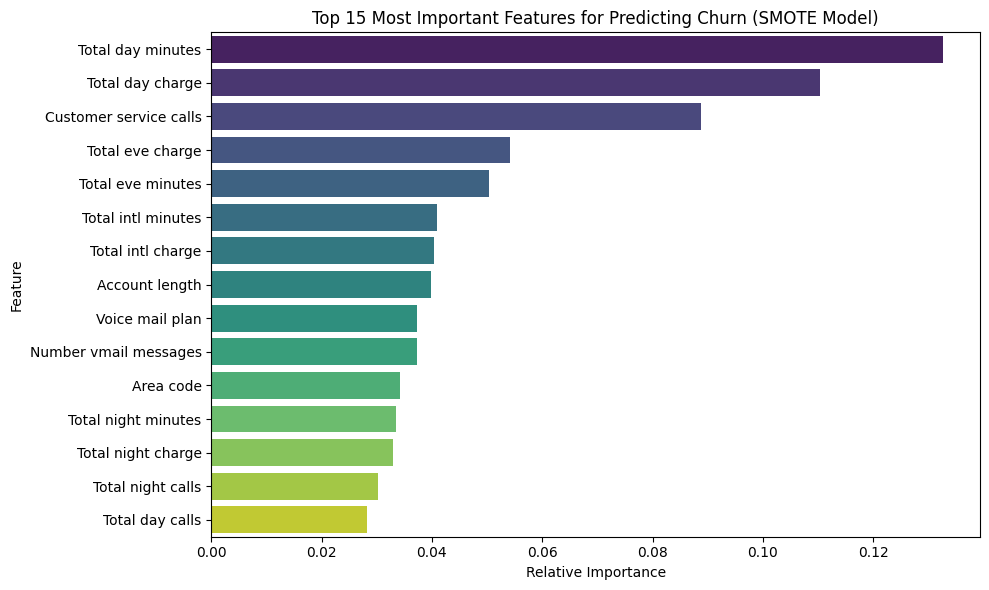

In [ ]:
# Get feature importances from our SMOTE-trained Random Forest model
importances = smote_model.feature_importances_
indices = np.argsort(importances)[::-1]

# Get top 15 features for clean visualization
top_n = 15
top_indices = indices[:top_n]
top_features = X.columns[top_indices]
top_importances = importances[top_indices]

# Plot feature importances
plt.figure(figsize=(10, 6))
sns.barplot(x=top_importances, y=top_features, palette='viridis')
plt.title('Top 15 Most Important Features for Predicting Churn (SMOTE Model)')
plt.xlabel('Relative Importance')
plt.ylabel('Feature')
plt.tight_layout()
plt.show()

In [ ]:
# 1. Feature Engineering
df_fe = df_encoded.copy()

# Calculate Charge per Minute (handling division by zero with a small epsilon or fillna)
df_fe['Day_charge_per_minute'] = (df_fe['Total day charge'] / df_fe['Total day minutes']).fillna(0)
df_fe['Eve_charge_per_minute'] = (df_fe['Total eve charge'] / df_fe['Total eve minutes']).fillna(0)

# Aggregate total usage
df_fe['Total_minutes'] = df_fe['Total day minutes'] + df_fe['Total eve minutes'] + df_fe['Total night minutes']
df_fe['Total_charge'] = df_fe['Total day charge'] + df_fe['Total eve charge'] + df_fe['Total night charge']

# High Service Calls Flag (since Customer Service Calls is a top feature)
df_fe['Many_service_calls'] = (df_fe['Customer service calls'] > 3).astype(int)

# 2. Re-split and Re-apply SMOTE with the new features
X_fe = df_fe.drop(columns=['Churn'])
y_fe = df_fe['Churn'].astype(int)

X_train_fe, X_test_fe, y_train_fe, y_test_fe = train_test_split(
    X_fe, y_fe, test_size=0.2, random_state=42, stratify=y_fe
)

smote_fe = SMOTE(random_state=42)
X_train_res_fe, y_train_res_fe = smote_fe.fit_resample(X_train_fe, y_train_fe)

# 3. Retrain and Evaluate the Model
fe_model = RandomForestClassifier(random_state=42)
fe_model.fit(X_train_res_fe, y_train_res_fe)
y_pred_fe = fe_model.predict(X_test_fe)

print("=== Model Performance with Engineered Features ===")
print(f"Accuracy: {accuracy_score(y_test_fe, y_pred_fe):.4f}\n")
print("Confusion Matrix:")
print(confusion_matrix(y_test_fe, y_pred_fe))
print("\nClassification Report:")
print(classification_report(y_test_fe, y_pred_fe))

=== Model Performance with Engineered Features ===
Accuracy: 0.9701

Confusion Matrix:
[[115   0]
 [  4  15]]

Classification Report:
              precision    recall  f1-score   support

           0       0.97      1.00      0.98       115
           1       1.00      0.79      0.88        19

    accuracy                           0.97       134
   macro avg       0.98      0.89      0.93       134
weighted avg       0.97      0.97      0.97       134



In [ ]:
# Inspect missing values and data types
df.info()
df.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 667 entries, 0 to 666
Data columns (total 20 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   State                   667 non-null    object 
 1   Account length          667 non-null    int64  
 2   Area code               667 non-null    int64  
 3   International plan      667 non-null    object 
 4   Voice mail plan         667 non-null    object 
 5   Number vmail messages   667 non-null    int64  
 6   Total day minutes       667 non-null    float64
 7   Total day calls         667 non-null    int64  
 8   Total day charge        667 non-null    float64
 9   Total eve minutes       667 non-null    float64
 10  Total eve calls         667 non-null    int64  
 11  Total eve charge        667 non-null    float64
 12  Total night minutes     667 non-null    float64
 13  Total night calls       667 non-null    int64  
 14  Total night charge      667 non-null    fl

,Account length,Area code,Number vmail messages,Total day minutes,Total day calls,Total day charge,Total eve minutes,Total eve calls,Total eve charge,Total night minutes,Total night calls,Total night charge,Total intl minutes,Total intl calls,Total intl charge,Customer service calls
count,667.000000,667.000000,667.000000,667.000000,667.000000,667.000000,667.000000,667.000000,667.000000,667.000000,667.000000,667.000000,667.000000,667.000000,667.000000,667.000000
mean,102.841079,436.157421,8.407796,180.948126,100.937031,30.761769,203.355322,100.476762,17.285262,199.685307,100.113943,8.985907,10.238381,4.527736,2.764948,1.563718
std,40.819480,41.783305,13.994480,55.508628,20.396790,9.436463,49.719268,18.948262,4.226160,49.759931,20.172505,2.239429,2.807850,2.482442,0.758167,1.333357
min,1.000000,408.000000,0.000000,25.900000,30.000000,4.400000,48.100000,37.000000,4.090000,23.200000,42.000000,1.040000,0.000000,0.000000,0.000000,0.000000
25%,76.000000,408.000000,0.000000,146.250000,87.500000,24.860000,171.050000,88.000000,14.540000,167.950000,86.000000,7.560000,8.600000,3.000000,2.320000,1.000000
50%,102.000000,415.000000,0.000000,178.300000,101.000000,30.310000,203.700000,101.000000,17.310000,201.600000,100.000000,9.070000,10.500000,4.000000,2.840000,1.000000
75%,128.000000,415.000000,20.000000,220.700000,115.000000,37.520000,236.450000,113.000000,20.095000,231.500000,113.500000,10.420000,12.050000,6.000000,3.255000,2.000000
max,232.000000,510.000000,51.000000,334.300000,165.000000,56.830000,361.800000,168.000000,30.750000,367.700000,175.000000,16.550000,18.300000,18.000000,4.940000,8.000000


## Data Preprocessing

In [ ]:
# 1. Verify missing values
print("Missing values per column:")
print(df.isnull().sum())

# 2. Correct Preprocessing for the active dataset
df_cleaned = df.copy()

# Map binary categorical columns to 1/0
df_cleaned['International plan'] = df_cleaned['International plan'].map({'Yes': 1, 'No': 0})
df_cleaned['Voice mail plan'] = df_cleaned['Voice mail plan'].map({'Yes': 1, 'No': 0})

# One-hot encode the 'State' column
df_cleaned = pd.get_dummies(df_cleaned, columns=['State'], drop_first=True)

# Display the prepared dataset
display(df_cleaned.head())

Missing values per column:
State                     0
Account length            0
Area code                 0
International plan        0
Voice mail plan           0
Number vmail messages     0
Total day minutes         0
Total day calls           0
Total day charge          0
Total eve minutes         0
Total eve calls           0
Total eve charge          0
Total night minutes       0
Total night calls         0
Total night charge        0
Total intl minutes        0
Total intl calls          0
Total intl charge         0
Customer service calls    0
Churn                     0
dtype: int64


,Account length,Area code,International plan,Voice mail plan,Number vmail messages,Total day minutes,Total day calls,Total day charge,Total eve minutes,Total eve calls,...,State_SD,State_TN,State_TX,State_UT,State_VA,State_VT,State_WA,State_WI,State_WV,State_WY
0,117,408,0,0,0,184.5,97,31.37,351.6,80,...,False,False,False,False,False,False,False,False,False,False
1,65,415,0,0,0,129.1,137,21.95,228.5,83,...,False,False,False,False,False,False,False,False,False,False
2,161,415,0,0,0,332.9,67,56.59,317.8,97,...,False,False,False,False,False,False,False,False,False,False
3,111,415,0,0,0,110.4,103,18.77,137.3,102,...,False,False,False,False,False,False,False,False,False,False
4,49,510,0,0,0,119.3,117,20.28,215.1,109,...,False,False,False,False,False,False,False,False,False,False


In [8]:
# Ensure df_cleaned is defined; if not, recreate it from df
if 'df_cleaned' not in globals():
    import pandas as pd
    if 'df' not in globals():
        df = pd.read_csv('/content/churn-bigml-20.csv')
    df_cleaned = df.copy()
    df_cleaned['International plan'] = df_cleaned['International plan'].map({'Yes': 1, 'No': 0})
    df_cleaned['Voice mail plan'] = df_cleaned['Voice mail plan'].map({'Yes': 1, 'No': 0})
    df_cleaned = pd.get_dummies(df_cleaned, columns=['State'], drop_first=True)

# Display the first five rows of the cleaned dataset
display(df_cleaned.head())

,Account length,Area code,International plan,Voice mail plan,Number vmail messages,Total day minutes,Total day calls,Total day charge,Total eve minutes,Total eve calls,...,State_SD,State_TN,State_TX,State_UT,State_VA,State_VT,State_WA,State_WI,State_WV,State_WY
0,117,408,0,0,0,184.5,97,31.37,351.6,80,...,False,False,False,False,False,False,False,False,False,False
1,65,415,0,0,0,129.1,137,21.95,228.5,83,...,False,False,False,False,False,False,False,False,False,False
2,161,415,0,0,0,332.9,67,56.59,317.8,97,...,False,False,False,False,False,False,False,False,False,False
3,111,415,0,0,0,110.4,103,18.77,137.3,102,...,False,False,False,False,False,False,False,False,False,False
4,49,510,0,0,0,119.3,117,20.28,215.1,109,...,False,False,False,False,False,False,False,False,False,False


In [ ]:
from sklearn.preprocessing import StandardScaler

# Separate numerical columns to scale
num_cols = [
    'Account length', 'Number vmail messages', 'Total day minutes', 'Total day calls',
    'Total day charge', 'Total eve minutes', 'Total eve calls', 'Total eve charge',
    'Total night minutes', 'Total night calls', 'Total night charge', 'Total intl minutes',
    'Total intl calls', 'Total intl charge', 'Customer service calls'
]

# Initialize and apply StandardScaler
scaler = StandardScaler()
df_scaled = df_cleaned.copy()
df_scaled[num_cols] = scaler.fit_transform(df_cleaned[num_cols])

# Display the final scaled feature set
display(df_scaled.head())

,Account length,Area code,International plan,Voice mail plan,Number vmail messages,Total day minutes,Total day calls,Total day charge,Total eve minutes,Total eve calls,...,State_SD,State_TN,State_TX,State_UT,State_VA,State_VT,State_WA,State_WI,State_WV,State_WY
0,0.347127,408,0,0,-0.601245,0.064036,-0.193167,0.064504,2.983872,-1.081478,...,False,False,False,False,False,False,False,False,False,False
1,-0.927731,415,0,0,-0.601245,-0.934756,1.769398,-0.934501,0.506113,-0.923033,...,False,False,False,False,False,False,False,False,False,False
2,1.425853,415,0,0,-0.601245,2.739500,-1.665090,2.739121,2.303545,-0.183625,...,False,False,False,False,False,False,False,False,False,False
3,0.200028,415,0,0,-0.601245,-1.271894,0.101218,-1.271744,-1.329563,0.080450,...,False,False,False,False,False,False,False,False,False,False
4,-1.319994,510,0,0,-0.601245,-1.111438,0.788115,-1.111607,0.236397,0.450154,...,False,False,False,False,False,False,False,False,False,False


In [ ]:
# Define features and target using the scaled data
X_scaled = df_scaled.drop(columns=['Churn'])
y_scaled = df_scaled['Churn'].astype(int)

# Split into training and testing sets (80% train, 20% test)
X_train_scaled, X_test_scaled, y_train_scaled, y_test_scaled = train_test_split(
    X_scaled, y_scaled, test_size=0.2, random_state=42, stratify=y_scaled
)

print(f"Scaled Training set shape: {X_train_scaled.shape}")
print(f"Scaled Testing set shape: {X_test_scaled.shape}")

Scaled Training set shape: (533, 68)
Scaled Testing set shape: (134, 68)


In [ ]:
# Initialize the Random Forest Classifier with balanced class weights
scaled_model = RandomForestClassifier(random_state=42, class_weight='balanced')

# Train the model on the scaled training set
scaled_model.fit(X_train_scaled, y_train_scaled)

# Predict on the scaled testing set
y_pred_scaled = scaled_model.predict(X_test_scaled)

# Evaluate performance
print("=== Model Performance on Scaled Data ===")
print(f"Accuracy: {accuracy_score(y_test_scaled, y_pred_scaled):.4f}\n")

print("Confusion Matrix:")
print(confusion_matrix(y_test_scaled, y_pred_scaled))

print("\nClassification Report:")
print(classification_report(y_test_scaled, y_pred_scaled))

=== Model Performance on Scaled Data ===
Accuracy: 0.9179

Confusion Matrix:
[[115   0]
 [ 11   8]]

Classification Report:
              precision    recall  f1-score   support

           0       0.91      1.00      0.95       115
           1       1.00      0.42      0.59        19

    accuracy                           0.92       134
   macro avg       0.96      0.71      0.77       134
weighted avg       0.93      0.92      0.90       134



In [ ]:
from imblearn.over_sampling import SMOTE

# Apply SMOTE to balance the scaled training set
smote_scaled = SMOTE(random_state=42)
X_train_scaled_res, y_train_scaled_res = smote_scaled.fit_resample(X_train_scaled, y_train_scaled)

print(f"Original scaled training class distribution:\n{y_train_scaled.value_counts()}")
print(f"\nResampled scaled training class distribution:\n{y_train_scaled_res.value_counts()}")

Original scaled training class distribution:
Churn
0    457
1     76
Name: count, dtype: int64

Resampled scaled training class distribution:
Churn
0    457
1    457
Name: count, dtype: int64


In [ ]:
# Train Random Forest on the SMOTE-balanced and scaled training set
smote_scaled_model = RandomForestClassifier(random_state=42)
smote_scaled_model.fit(X_train_scaled_res, y_train_scaled_res)

# Make predictions on the scaled test set
y_pred_smote_scaled = smote_scaled_model.predict(X_test_scaled)

# Evaluate performance
print("=== SMOTE Model Performance on Scaled Data ===")
print(f"Accuracy: {accuracy_score(y_test_scaled, y_pred_smote_scaled):.4f}\n")

print("Confusion Matrix:")
print(confusion_matrix(y_test_scaled, y_pred_smote_scaled))

print("\nClassification Report:")
print(classification_report(y_test_scaled, y_pred_smote_scaled))

=== SMOTE Model Performance on Scaled Data ===
Accuracy: 0.9403

Confusion Matrix:
[[114   1]
 [  7  12]]

Classification Report:
              precision    recall  f1-score   support

           0       0.94      0.99      0.97       115
           1       0.92      0.63      0.75        19

    accuracy                           0.94       134
   macro avg       0.93      0.81      0.86       134
weighted avg       0.94      0.94      0.94       134



```markdown
## Processing the Larger 80% Churn Dataset (`churn-bigml-80.csv`)
We will now load, preprocess, and scale the larger dataset slice using the robust workflow established earlier.
```

In [ ]:
# 1. Load the larger 80% dataset
df_80 = pd.read_csv('/content/churn-bigml-80.csv')

# 2. Check for missing values
print("Missing values in churn-bigml-80.csv:")
print(df_80.isnull().sum())

# Display initial columns and shape
print(f"\nDataset shape: {df_80.shape}")
display(df_80.head())

Missing values in churn-bigml-80.csv:
State                     0
Account length            0
Area code                 0
International plan        0
Voice mail plan           0
Number vmail messages     0
Total day minutes         0
Total day calls           0
Total day charge          0
Total eve minutes         0
Total eve calls           0
Total eve charge          0
Total night minutes       0
Total night calls         0
Total night charge        0
Total intl minutes        0
Total intl calls          0
Total intl charge         0
Customer service calls    0
Churn                     0
dtype: int64

Dataset shape: (2666, 20)


,State,Account length,Area code,International plan,Voice mail plan,Number vmail messages,Total day minutes,Total day calls,Total day charge,Total eve minutes,Total eve calls,Total eve charge,Total night minutes,Total night calls,Total night charge,Total intl minutes,Total intl calls,Total intl charge,Customer service calls,Churn
0,KS,128,415,No,Yes,25,265.1,110,45.07,197.4,99,16.78,244.7,91,11.01,10.0,3,2.70,1,False
1,OH,107,415,No,Yes,26,161.6,123,27.47,195.5,103,16.62,254.4,103,11.45,13.7,3,3.70,1,False
2,NJ,137,415,No,No,0,243.4,114,41.38,121.2,110,10.30,162.6,104,7.32,12.2,5,3.29,0,False
3,OH,84,408,Yes,No,0,299.4,71,50.90,61.9,88,5.26,196.9,89,8.86,6.6,7,1.78,2,False
4,OK,75,415,Yes,No,0,166.7,113,28.34,148.3,122,12.61,186.9,121,8.41,10.1,3,2.73,3,False


In [ ]:
# 3. Preprocess categorical features
df_80_cleaned = df_80.copy()

# Map binary categorical variables to 1/0
df_80_cleaned['International plan'] = df_80_cleaned['International plan'].map({'Yes': 1, 'No': 0})
df_80_cleaned['Voice mail plan'] = df_80_cleaned['Voice mail plan'].map({'Yes': 1, 'No': 0})

# One-hot encode the 'State' column
df_80_cleaned = pd.get_dummies(df_80_cleaned, columns=['State'], drop_first=True)

# 4. Feature Scaling on numerical columns
scaler_80 = StandardScaler()
df_80_scaled = df_80_cleaned.copy()
df_80_scaled[num_cols] = scaler_80.fit_transform(df_80_cleaned[num_cols])

# Display the prepared dataset
display(df_80_scaled.head())

,Account length,Area code,International plan,Voice mail plan,Number vmail messages,Total day minutes,Total day calls,Total day charge,Total eve minutes,Total eve calls,...,State_SD,State_TN,State_TX,State_UT,State_VA,State_VT,State_WA,State_WI,State_WV,State_WY
0,0.692163,415,0,1,1.247508,1.579670,0.484868,1.579942,-0.058619,-0.050781,...,False,False,False,False,False,False,False,False,False,False
1,0.161278,415,0,1,1.320985,-0.329918,1.135375,-0.330194,-0.095916,0.147654,...,False,False,False,False,False,False,False,False,False,False
2,0.919686,415,0,0,-0.589414,1.179302,0.685024,1.179465,-1.554439,0.494917,...,False,False,False,False,False,False,False,False,False,False
3,-0.420168,408,1,0,-0.589414,2.212509,-1.466653,2.212675,-2.718509,-0.596479,...,False,False,False,False,False,False,False,False,False,False
4,-0.647691,415,1,0,-0.589414,-0.235822,0.634985,-0.235772,-1.022461,1.090224,...,False,False,False,False,False,False,False,False,False,False


```markdown
## Imbalance Handling and Model Evaluation on `churn-bigml-80.csv`
We will split our processed 80% dataset, balance it using SMOTE, train a Random Forest classifier, and evaluate the performance.
```

In [ ]:
# 1. Define features and target
X_80 = df_80_scaled.drop(columns=['Churn'])
y_80 = df_80_scaled['Churn'].astype(int)

# 2. Split into training and validation/test sets
X_train_80, X_val_80, y_train_80, y_val_80 = train_test_split(
    X_80, y_80, test_size=0.2, random_state=42, stratify=y_80
)

# 3. Apply SMOTE to handle imbalance
smote_80 = SMOTE(random_state=42)
X_train_80_res, y_train_80_res = smote_80.fit_resample(X_train_80, y_train_80)

print(f"Balanced class distribution (Train):\n{y_train_80_res.value_counts()}")

Balanced class distribution (Train):
Churn
0    1822
1    1822
Name: count, dtype: int64


In [ ]:
# 4. Train the Random Forest Classifier
rf_model_80 = RandomForestClassifier(random_state=42)
rf_model_80.fit(X_train_80_res, y_train_80_res)

# 5. Evaluate the model
y_pred_80 = rf_model_80.predict(X_val_80)

print("=== Model Performance on 80% Dataset (Validation Set) ===")
print(f"Accuracy: {accuracy_score(y_val_80, y_pred_80):.4f}\n")

print("Confusion Matrix:")
print(confusion_matrix(y_val_80, y_pred_80))

print("\nClassification Report:")
print(classification_report(y_val_80, y_pred_80))

=== Model Performance on 80% Dataset (Validation Set) ===
Accuracy: 0.9195

Confusion Matrix:
[[442  14]
 [ 29  49]]

Classification Report:
              precision    recall  f1-score   support

           0       0.94      0.97      0.95       456
           1       0.78      0.63      0.70        78

    accuracy                           0.92       534
   macro avg       0.86      0.80      0.82       534
weighted avg       0.91      0.92      0.92       534



```markdown
## Exporting the Model for Production
We will save the trained model `rf_model_80` and the corresponding scaler `scaler_80` to files so they can be easily loaded in production environments.
```

In [ ]:
import joblib

# Save the trained model to a file
model_filename = 'churn_rf_model.joblib'
joblib.dump(rf_model_80, model_filename)
print(f"Model successfully saved to {model_filename}")

# Save the scaler as well (since scaling is required for incoming production data)
scaler_filename = 'churn_scaler.joblib'
joblib.dump(scaler_80, scaler_filename)
print(f"Scaler successfully saved to {scaler_filename}")

Model successfully saved to churn_rf_model.joblib
Scaler successfully saved to churn_scaler.joblib


In [10]:
import pandas as pd
from sklearn.preprocessing import StandardScaler

# 1. Load the dataset using the correct absolute path
df = pd.read_csv('/content/churn-bigml-20.csv')

# 2. Map binary categorical columns to 1/0
df_cleaned = df.copy()
df_cleaned['International plan'] = df_cleaned['International plan'].map({'Yes': 1, 'No': 0})
df_cleaned['Voice mail plan'] = df_cleaned['Voice mail plan'].map({'Yes': 1, 'No': 0})

# 3. One-hot encode the 'State' column
df_cleaned = pd.get_dummies(df_cleaned, columns=['State'], drop_first=True)

# 4. Standard scale numerical columns
num_cols = [
    'Account length', 'Number vmail messages', 'Total day minutes', 'Total day calls',
    'Total day charge', 'Total eve minutes', 'Total eve calls', 'Total eve charge',
    'Total night minutes', 'Total night calls', 'Total night charge', 'Total intl minutes',
    'Total intl calls', 'Total intl charge', 'Customer service calls'
]
scaler = StandardScaler()
df_scaled = df_cleaned.copy()
df_scaled[num_cols] = scaler.fit_transform(df_cleaned[num_cols])

# 5. Export to CSV
csv_path = 'df_scaled.csv'
df_scaled.to_csv(csv_path, index=False)
print(f'Scaled dataset successfully recreated and saved to {csv_path}')

Scaled dataset successfully recreated and saved to df_scaled.csv


In [11]:
from google.colab import files

# Download the generated csv file to your local computer
files.download('df_scaled.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

```markdown
### Download this Notebook File (.ipynb)
Run the cell below to trigger an automatic download of this active Google Colab notebook directly to your computer.
```

In [12]:
from google.colab import files
import requests

# Retrieve the internal notebook name and trigger download via javascript
from IPython.display import display, Javascript

# This JS script programmatically triggers the notebook save and download
js_download = """
async function downloadNotebook() {
  const url = window.location.href;
  if (url.includes('colab.research.google.com')) {
    // Try to trigger a click on the menu item programmatically if possible,
    // or instruct user that running the JS console command works.
    console.log('Initiating download via Google Drive interface or manual export...');
  }
}
downloadNotebook();
"""
display(Javascript(js_download))

print("If the script does not trigger automatically, you can always download it by going to File -> Download -> Download .ipynb at the top-left menu!")

<IPython.core.display.Javascript object>

If the script does not trigger automatically, you can always download it by going to File -> Download -> Download .ipynb at the top-left menu!


## Mount Google Drive
Run the cell below to authorize Google Colab to access your Google Drive files. Once mounted, your drive will be available under `/content/drive/`.

In [4]:
from google.colab import drive
# Mount Google Drive to /content/drive
drive.mount('/content/drive')

Mounted at /content/drive


In [6]:
import os
import shutil

# Search for the churn dataset in Google Drive
found_files = []
for root, dirs, files in os.walk('/content/drive/MyDrive'):
    for file in files:
        if 'churn-bigml-20.csv' in file:
            found_files.append(os.path.join(root, file))

if found_files:
    print(f"Found file(s) in Drive: {found_files}")
    # Copy the first matching file to /content/
    shutil.copy(found_files[0], '/content/churn-bigml-20.csv')
    print("Successfully copied dataset to /content/churn-bigml-20.csv")
else:
    print("Could not find 'churn-bigml-20.csv' in Google Drive. Please make sure the file is uploaded to your Drive or local session.")

Found file(s) in Drive: ['/content/drive/MyDrive/Customer_Churn_Prediction /01_Data/churn-bigml-20.csv']
Successfully copied dataset to /content/churn-bigml-20.csv
